DATA SHAPE: (500, 7)

HEAD:
   Age  Gender  BloodPressure  Cholesterol  HeartRate  QuantumPatternFeature  \
0   68       1            105          191        107               8.362241   
1   58       0             97          249         89               9.249002   
2   44       0             93          190         82               7.942542   
3   72       1             93          183        101               6.495155   
4   37       0            145          166        103               7.653900   
5   50       1            114          271         73               8.631604   
6   68       1            156          225         73               7.559545   
7   48       0            156          236         61               9.152103   
8   52       0            116          266        114               9.146932   
9   40       1            121          255         96               9.683800   

   HeartDisease  
0             1  
1             0  
2             1  
3             1  
4

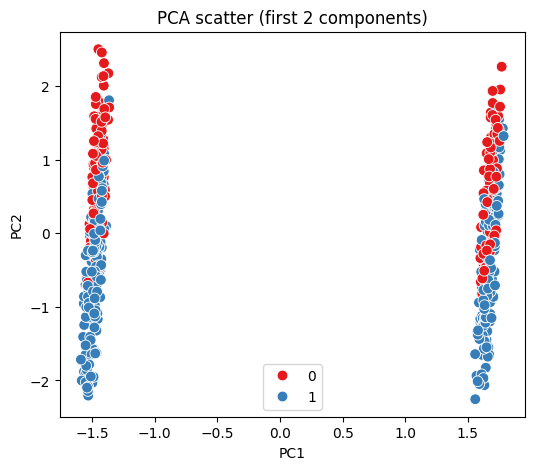


Feature correlation with label (Pearson):
  Age                    corr=0.2583
  Gender                 corr=-0.0115
  BloodPressure          corr=-0.1170
  Cholesterol            corr=-0.4235
  HeartRate              corr=-0.1027
  QuantumPatternFeature  corr=-0.7752

Parity mapping examples (bitstring -> label):
  000000 -> parity sum 0 -> label 1
  111111 -> parity sum 6 -> label 1
  101010 -> parity sum 3 -> label 0
  010101 -> parity sum 3 -> label 0
  100000 -> parity sum 1 -> label 0

***DIAGNOSTIC RUN COMPLETED***



In [1]:
# diagnosis_qml_debug.py
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- Config ----------
FILE_NAME = "Heart_data.csv"
TEST_SIZE = 0.2
RANDOM_SEED = 24
PCA_COMPONENTS = 3
SCALE_TO_PI = True  # keep same mapping as your feature map pipeline
# ----------------------------

# 1) Load data
df = pd.read_csv(FILE_NAME)
print("DATA SHAPE:", df.shape)
print("\nHEAD:")
print(df.head(10))
print("\nCOLUMNS:", df.columns.tolist())

# 2) Labels & balance
y = df['HeartDisease'].astype(int).values
unique, counts = np.unique(y, return_counts=True)
print("\nLABEL DISTRIBUTION:")
for u, c in zip(unique, counts):
    print(f"  Label {u}: {c} samples ({c/len(y)*100:.2f}%)")

# 3) Features
feature_cols = ['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate', 'QuantumPatternFeature']
X = df[feature_cols].astype(float).values

# basic stats
print("\nFEATURE STATS (min, max, mean, std):")
for i, col in enumerate(feature_cols):
    print(f"  {col:22s} min={X[:,i].min():.3f} max={X[:,i].max():.3f} mean={X[:,i].mean():.3f} std={X[:,i].std():.3f}")

# 4) Normalize to [0,1] then optionally to [0, pi] (to be compatible with your QNN pipeline)
scaler = MinMaxScaler()
X_norm = scaler.fit_transform(X)
if SCALE_TO_PI:
    X_for_featuremap = X_norm * np.pi
else:
    X_for_featuremap = X_norm.copy()

# 5) PCA diagnostics
pca = PCA(n_components=min(PCA_COMPONENTS, X_for_featuremap.shape[1]), random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_for_featuremap)
print("\nPCA EXPLAINED VARIANCE RATIO (components):", pca.explained_variance_ratio_)
print("PCA cumulative explained:", np.cumsum(pca.explained_variance_ratio_))

# 6) Train-test split (stratify to preserve class ratio)
X_train_norm, X_test_norm, y_train, y_test = train_test_split(X_for_featuremap, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y)
X_train_pca, X_test_pca, _, _ = train_test_split(X_pca, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y)

print("\nSPLIT SIZES:", X_train_norm.shape, X_test_norm.shape)

# helper to run models
def run_and_report(clf, Xtr, Xte, ytr, yte, name="model"):
    clf.fit(Xtr, ytr)
    pred = clf.predict(Xte)
    acc = accuracy_score(yte, pred)
    print(f"\n{name} accuracy: {acc*100:.2f}%")
    print("Classification report:\n", classification_report(yte, pred))
    cm = confusion_matrix(yte, pred)
    print("Confusion matrix:\n", cm)
    return acc, pred, cm

# 7) Classical baselines on normalized data (full features)
print("\n--- CLASSICAL BASELINES on normalized features (full) ---")
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED)
svm = SVC(kernel='rbf', gamma='scale', probability=False, random_state=RANDOM_SEED)

acc_lr_full, pred_lr_full, cm_lr_full = run_and_report(lr, X_train_norm, X_test_norm, y_train, y_test, "LogisticRegression (full)")
acc_rf_full, pred_rf_full, cm_rf_full = run_and_report(rf, X_train_norm, X_test_norm, y_train, y_test, "RandomForest (full)")
acc_svm_full, pred_svm_full, cm_svm_full = run_and_report(svm, X_train_norm, X_test_norm, y_train, y_test, "SVM-RBF (full)")

# 8) Classical baselines on PCA features
print("\n--- CLASSICAL BASELINES on PCA-reduced features ---")
acc_lr_pca, pred_lr_pca, cm_lr_pca = run_and_report(LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
                                                    X_train_pca, X_test_pca, y_train, y_test, "LogisticRegression (PCA)")
acc_rf_pca, pred_rf_pca, cm_rf_pca = run_and_report(RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED),
                                                    X_train_pca, X_test_pca, y_train, y_test, "RandomForest (PCA)")
acc_svm_pca, pred_svm_pca, cm_svm_pca = run_and_report(SVC(kernel='rbf', gamma='scale', random_state=RANDOM_SEED),
                                                       X_train_pca, X_test_pca, y_train, y_test, "SVM-RBF (PCA)")

# 9) Quick visualization: 2D PCA scatter (colored by label)
if X_pca.shape[1] >= 2:
    plt.figure(figsize=(6,5))
    sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y, palette="Set1", s=60)
    plt.title("PCA scatter (first 2 components)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()

# 10) Feature correlation with label (point biserial approx using pearson against binary label)
print("\nFeature correlation with label (Pearson):")
for i, col in enumerate(feature_cols):
    corr = np.corrcoef(X[:,i], y)[0,1]
    print(f"  {col:22s} corr={corr:.4f}")

# 11) Simple parity-mapping QNN sanity check (use a VERY small mock using statevector from qiskit for single example)
#    We will just check mapping function parity->label for a couple of toy bitstrings to ensure mapping isn't reversed.
def parity_to_label(bitstring):
    bit_sum = sum(int(k) for k in bitstring if k in ('0','1'))
    return (bit_sum + 1) % 2

test_bits = ['0'*6, '1'*6, '101010', '010101', '100000']
print("\nParity mapping examples (bitstring -> label):")
for b in test_bits:
    print(f"  {b} -> parity sum {sum(int(k) for k in b)} -> label {parity_to_label(b)}")

print("\n***DIAGNOSTIC RUN COMPLETED***\n")
